# Spatial 2D object hidden state

**VS Code native research demonstration — synthetic material, completed numerical pilot.**

Open the project in VS Code, run **Dev Containers: Reopen in Container**, then open this notebook.
Select **NR Spatial 2D (Linux)** (Python `/opt/venv/bin/python`) and choose **Restart**, then **Run All**.
The interface stays in VS Code. Code and results are saved in the mounted project directory.
Setup, commands and measured checks: `docs/spatial_2d/CONTAINER.md`.
The original Windows `.venv` and its recorded results remain available for legacy reproduction.

The notebook uses the same Python implementation as `python -m nr2d.cli demo`.
The default solves a fresh lightweight main episode and replays provenance-checked verification/prediction caches;
missing caches are computed on CPU.
Set `RECOMPUTE_PILOT = True` below to generate a fresh run while retaining the previous one.
Dropdown changes are inert until a **Run** button is pressed. The time slider only replays results.

The question is whether action-observation history improves *future interaction prediction*.
This is not a claim that long history, a neural model, or a new controller is necessary.
Archived E1/E2/E3 remain separate; E3's negative action result is not replaced by this prediction pilot.


In [1]:
from pathlib import Path
import os
import sys
import time

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/nr2d/physics.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Open the NR-material-state folder in VS Code and run from this project.')
sys.path.insert(0, str(ROOT / 'src'))
get_ipython().run_line_magic('matplotlib', 'widget')

import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from nr2d.physics import Config, SpatialModel, Trace
from nr2d.protocols import protocol
from nr2d.experiments import run_pilot, read_json, write_json, forecasts_for, sweep_for
from nr2d.plotting import archived_e1_figure, paired_figure, export_figure
from nr2d.widgets import ReplayDashboard, ForecastDashboard, SweepDashboard, checks_table, matching_table, table
import ipywidgets as widgets

NOTEBOOK_START = time.perf_counter()
RECOMPUTE_PILOT = False
print('Python:', sys.executable)
print('Project:', ROOT)


Python: /opt/venv/bin/python
Project: /workspaces/NR-material-state


## 0. Connect the existing evidence

This is **archived E1, a 1D model**. It verifies the plotting/data path only.
E1/E2 motivate state inference; competitive short classical observers and the negative E3 action result constrain our claims.
All spatial meshes and results below come from the new 2D solver.


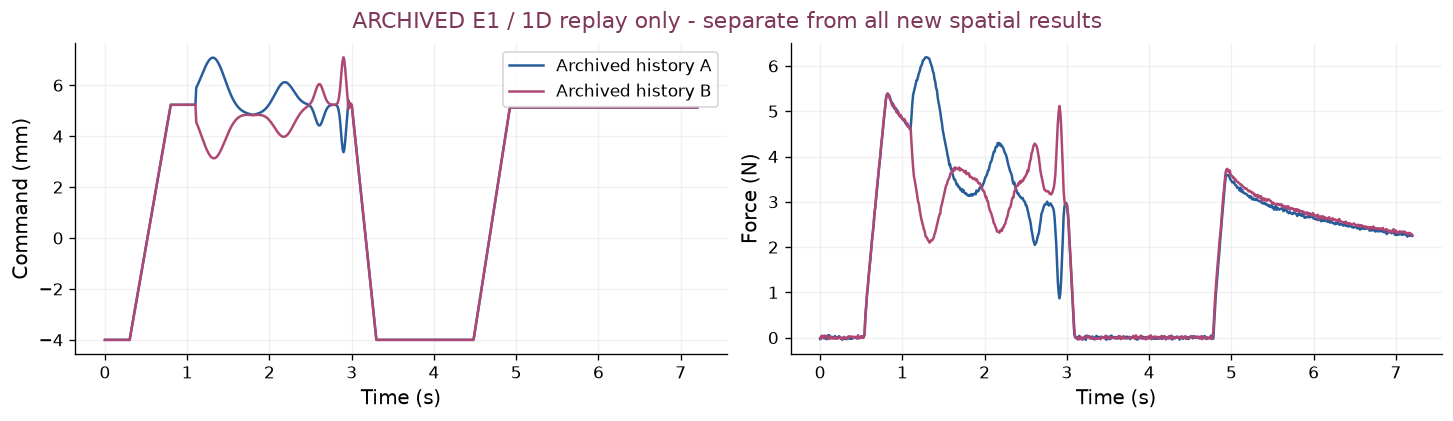

Archived source: early experiment/experiments/01_history/runs/round2_v1/data/test_wait.npz


In [2]:
from io import BytesIO
with plt.ioff():
    archived_fig, archived_source = archived_e1_figure()
buffer = BytesIO()
archived_fig.savefig(buffer, format='png', dpi=120, bbox_inches='tight')
display(Image(data=buffer.getvalue()))
plt.close(archived_fig)
print('Archived source:', archived_source.relative_to(ROOT))


## 1. Physical process: load → hold → release → wait → recontact

The body is a 40 × 20 mm plane-strain domain with a fixed bottom and traction-free sides.
A circular, frictionless rigid indenter is driven by a finite-stiffness, damped actuator with tool inertia.
Body equilibrium is **quasistatic**, not full elastodynamics. Lateral displacement is solved by FEM, not prescribed.

The synthetic constitutive law is

$$
\sigma = C_\infty\epsilon + \sum_{i\in\{f,s\}} C_i(\epsilon-z_i),\qquad
\dot z_i=(\epsilon-z_i)/\tau_i.
$$

Here $z_f,z_s$ are spatial internal-strain fields; they are not two spatial coordinates or directly measured forces.
The physical predictive state consists of these fields plus tool position/velocity and known context.
Displacement/contact equilibrium is solved from that state. The circular contact penalty includes equal and opposite reactions.
The command, achieved movement and contact reaction are logged separately at a synthetic 100 Hz.


In [3]:
run, runtime = run_pilot(Config(), force=RECOMPUTE_PILOT, progress=print)
manifest = read_json(run / 'manifest.json')
report = read_json(run / 'checks.json')
from datetime import datetime
commands, phases, _ = protocol(Config(**read_json(run / 'config.json')))
main = SpatialModel(Config(**read_json(run / 'config.json'))).simulate(
    commands, phases, metadata={'source': 'Fresh notebook spatial 2D solve', 'role': 'demonstration'})
live_dir = run / 'notebook_runs' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
main.save(live_dir / 'main.npz')
write_json(live_dir / 'execution.json', {'solver_seconds': main.wall_seconds, 'source': 'fresh main episode',
                                      'config': main.config, 'verification_cache': str(run / 'checks.json')})
print('Mode:', runtime['mode'])
print('This numerical entry call: %.2f s; recorded cold pilot: %.2f s' %
      (runtime['wall_seconds'], manifest['wall_seconds']))
print('Run:', run)
print('Synthetic parameters:', main.config)
print('FRESH main spatial solve: %.2f s; verification table below replays the checked numerical pilot.' % main.wall_seconds)
display(checks_table(report))


REPLAY: verified cached spatial 2D pilot (pilot_c9dd23016896)
Mode: REPLAY
This numerical entry call: 0.04 s; recorded cold pilot: 72.34 s
Run: /workspaces/NR-material-state/runs/2d_contact/pilot_c9dd23016896
Synthetic parameters: {'nx': 24, 'ny': 12, 'width': 0.04, 'height': 0.02, 'thickness': 0.01, 'radius': 0.03, 'E_inf': 20000.0, 'E_fast': 40000.0, 'E_slow': 60000.0, 'nu': 0.35, 'tau_fast': 0.12, 'tau_slow': 0.9, 'tool_mass': 0.04, 'actuator_k': 5000.0, 'actuator_c': 12.0, 'penalty': 2000000000.0, 'dt': 0.01, 'clearance': 0.00015, 'newton_tol': 1e-08, 'newton_max': 35}
FRESH main spatial solve: 1.29 s; verification table below replays the checked numerical pilot.


HTML(value='<table><thead><tr><th style="padding:6px 12px;border-bottom:1px solid #ddd;text-align:left">Physic…

In [4]:
replay = ReplayDashboard(main)
display(replay.widget)


**Reading the animation.** The mesh uses physical geometry at 1× displacement scale.
The colored field is privileged slow internal strain; orange points mark active contact and teal points are lateral sensors.
All three curves share the mesh's time cursor. Outward marker displacement is shown in micrometers so small lateral motion remains visible.
The force and tool-displacement units are N and mm. The body can continue recovering while the tool is detached and contact force is zero.

The compact checks compare relaxation/recovery with analytic references, include an elastic control, enforce contact separation,
check force balance and strain range, and repeat the episode under mesh, time-step and penalty refinement.
Passing these gates supports this **synthetic numerical regime**, not a validated real material or a full 3D robot.


## 2. Why the current observation may be insufficient

The two histories below are generated by feasible command sequences from relaxed starts.
Selection uses current actual position, velocity, force, and **both lateral markers**, under declared synthetic sensor resolution.
Command, elapsed time, material, geometry and tool parameters also match. No future response participates in selection.
The selection rule is the first accepted pair in fixed ID order. Every attempted pair and parent history is saved.

**A finite-resolution match is not exact observational equality.** Lateral shape contains some current-state information.
The 5 um marker band is a declared matching tolerance, not an implemented quantizer. Estimators retain raw marker readings
plus the selected Gaussian noise. They can exploit residual shape differences within that band.
Use the residual table to judge the pair's similarity; this is not a proof that the full current observation is uninformative.


HTML(value='<table><thead><tr><th style="padding:6px 12px;border-bottom:1px solid #ddd;text-align:left">Curren…

Accepted / attempted: 28 / 28
Independent test histories: 8


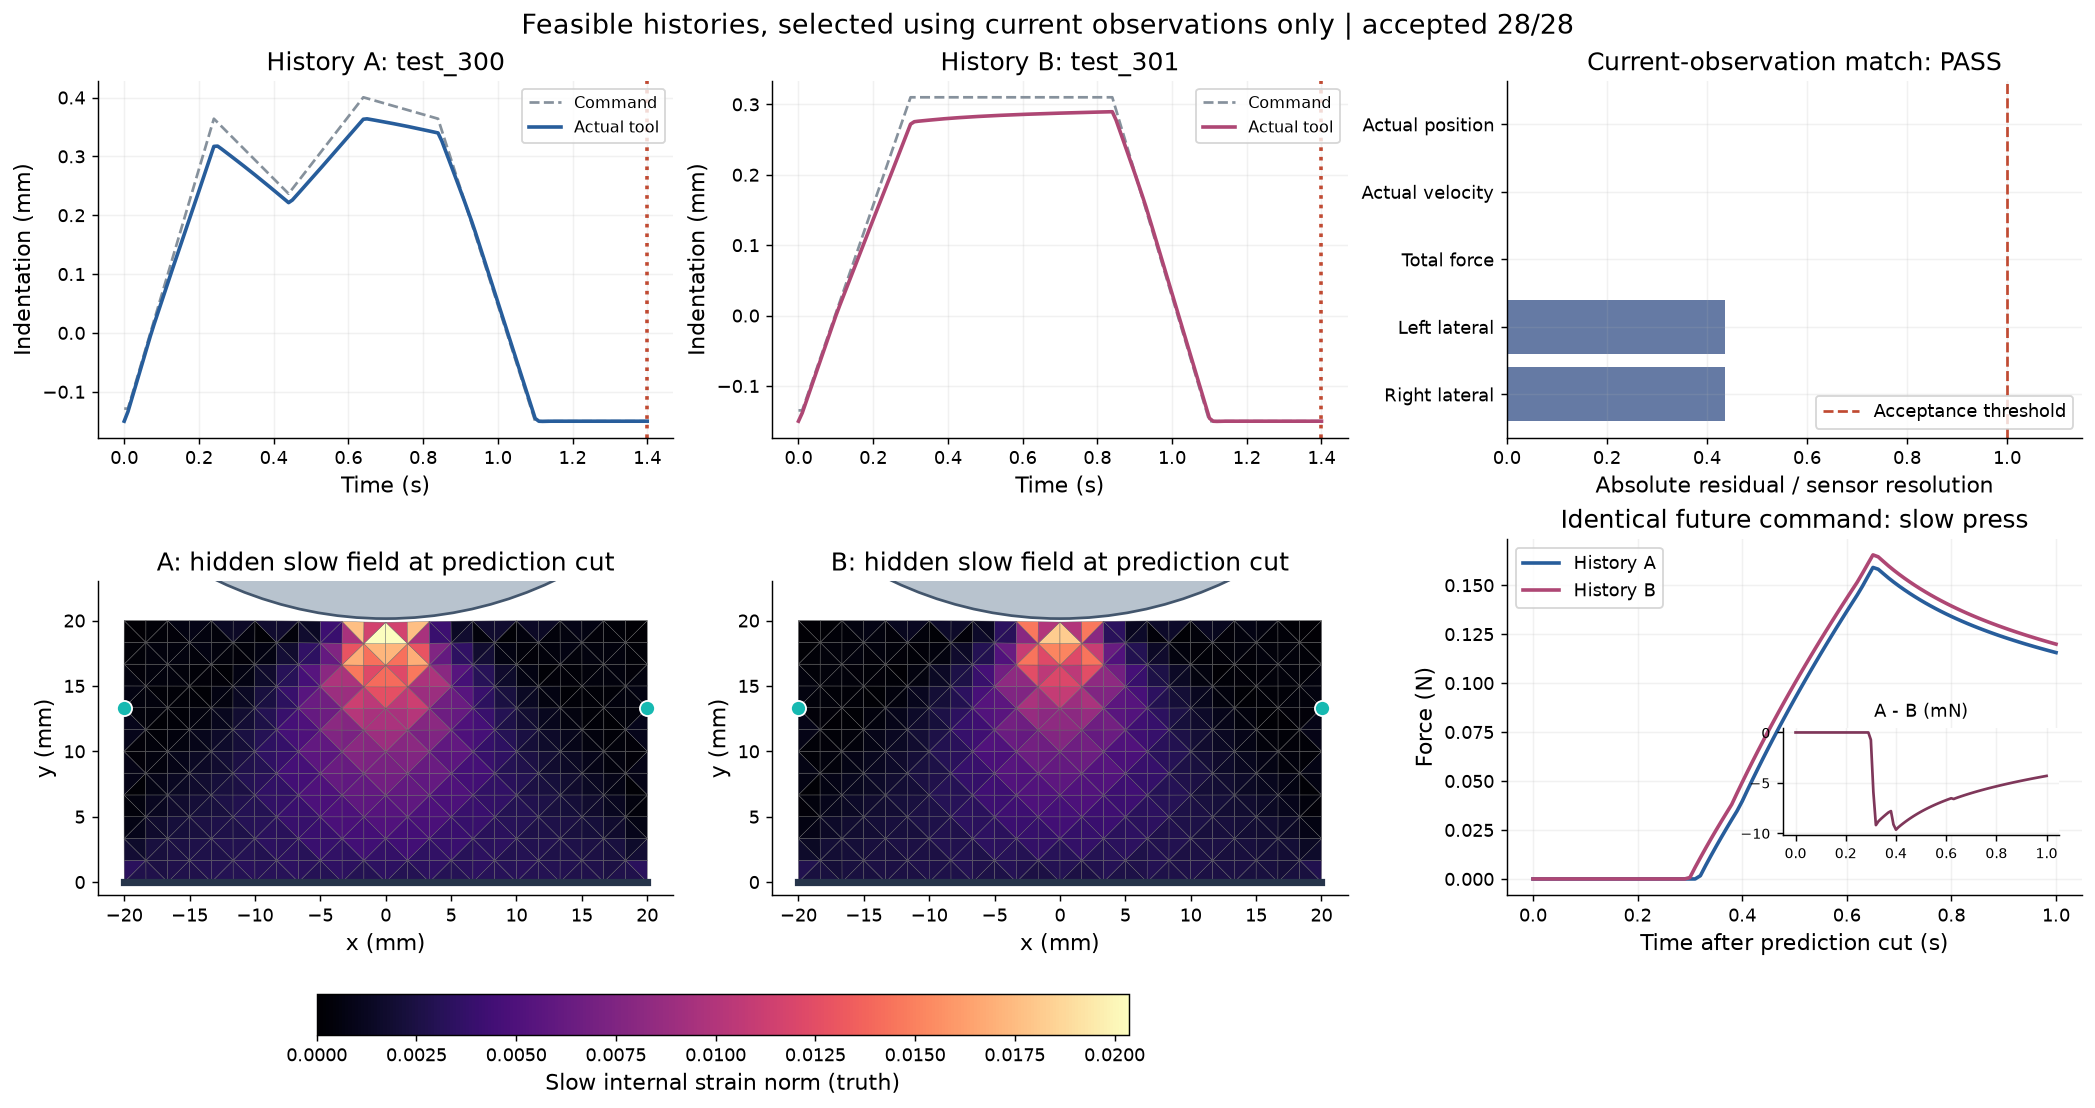

Future force-contrast RMS: 5.583 mN (default), 5.598 mN (fine mesh)
Contrast change under mesh refinement: 0.382 mN RMS


In [5]:
matching = read_json(run / 'matching.json')
display(matching_table(run))
print('Accepted / attempted:', matching['accepted'], '/', matching['attempted'])
print('Independent test histories:', manifest['independent_test_history_count'])
with plt.ioff():
    pair_fig = paired_figure(run)
buffer = BytesIO()
pair_fig.savefig(buffer, format='png', dpi=130, bbox_inches='tight')
display(Image(data=buffer.getvalue()))
plt.close(pair_fig)
refinement = read_json(run / 'pair_refinement.json')
print('Future force-contrast RMS: %.3f mN (default), %.3f mN (fine mesh)' %
      (refinement['default']['force_contrast_rms_N']*1e3, refinement['fine']['force_contrast_rms_N']*1e3))
print('Contrast change under mesh refinement: %.3f mN RMS' % (refinement['contrast_discretization_rms_N']*1e3))


## 3. One checkpoint, several future actions

Choose History A/B and a future speed, hold or release, then press **Run selected future**.
Each branch copies a physically reached checkpoint and uses the same future command for all methods.
No predictor receives future achieved movement, future force or future truth labels.
The current checkpoint is detached: **Hold/Release should give zero force**. This is an informative negative control.

| Method | Information and approximation |
|---|---|
| Snapshot | Current position, velocity, force and two markers; six-coefficient model-derived initial-strain basis, minimum-norm fit |
| Short classical | Same model and sensors over the last 0.2 s; same fitting basis and optimizer cap |
| Full classical | Complete measured movement history **and known relaxed initial state**; exact-model replay |
| True state | Privileged complete internal fields at the checkpoint; numerical reference under the same future commands |

All methods receive the same known material/contact/actuator parameters. The finite-window methods fit force and lateral channels;
full replay only needs achieved movement under its stronger initialization assumption.
The snapshot and short-window methods share an optimizer cap, but longer windows cost more; full replay uses a different algorithm.
Report measured inference time rather than claiming identical compute. The basis is a modeling approximation, not a learned representation.
True-state rollout is not a globally optimal control policy.


In [6]:
forecast = ForecastDashboard(run)
display(forecast.widget)


## 4. How much history is actually needed?

Compare 0, 0.04, 0.1, 0.2, 0.4, 0.8 s and full history on a separate validation parent.
Noise levels are **synthetic**: nominal standard deviations are 0.5 um position, 0.01 mm/s velocity,
1.5 mN force and 1 um for each marker. The same noisy realization is shared across methods.
Sampling is synchronous with zero artificial latency here; robot timing and latency have not been measured.
The pulse changes only the physically executed loading history. It is not hidden-state editing.

Changing options does not run a sweep. Press the button; progress and cache/recompute status are shown explicitly.
Short windows may be sufficient, longer windows need not improve monotonically, and optimizer failures remain in the logs.


In [7]:
sweep = SweepDashboard(run)
display(sweep.widget)


**Read the negative noise result too.** The saved comparison below includes both validation excitation conditions.
Its nominal-noise short windows can be worse than snapshot. The batch table in `RESULTS.md` reports all eight test parents;
these two validation traces are not independent evidence for a population claim.


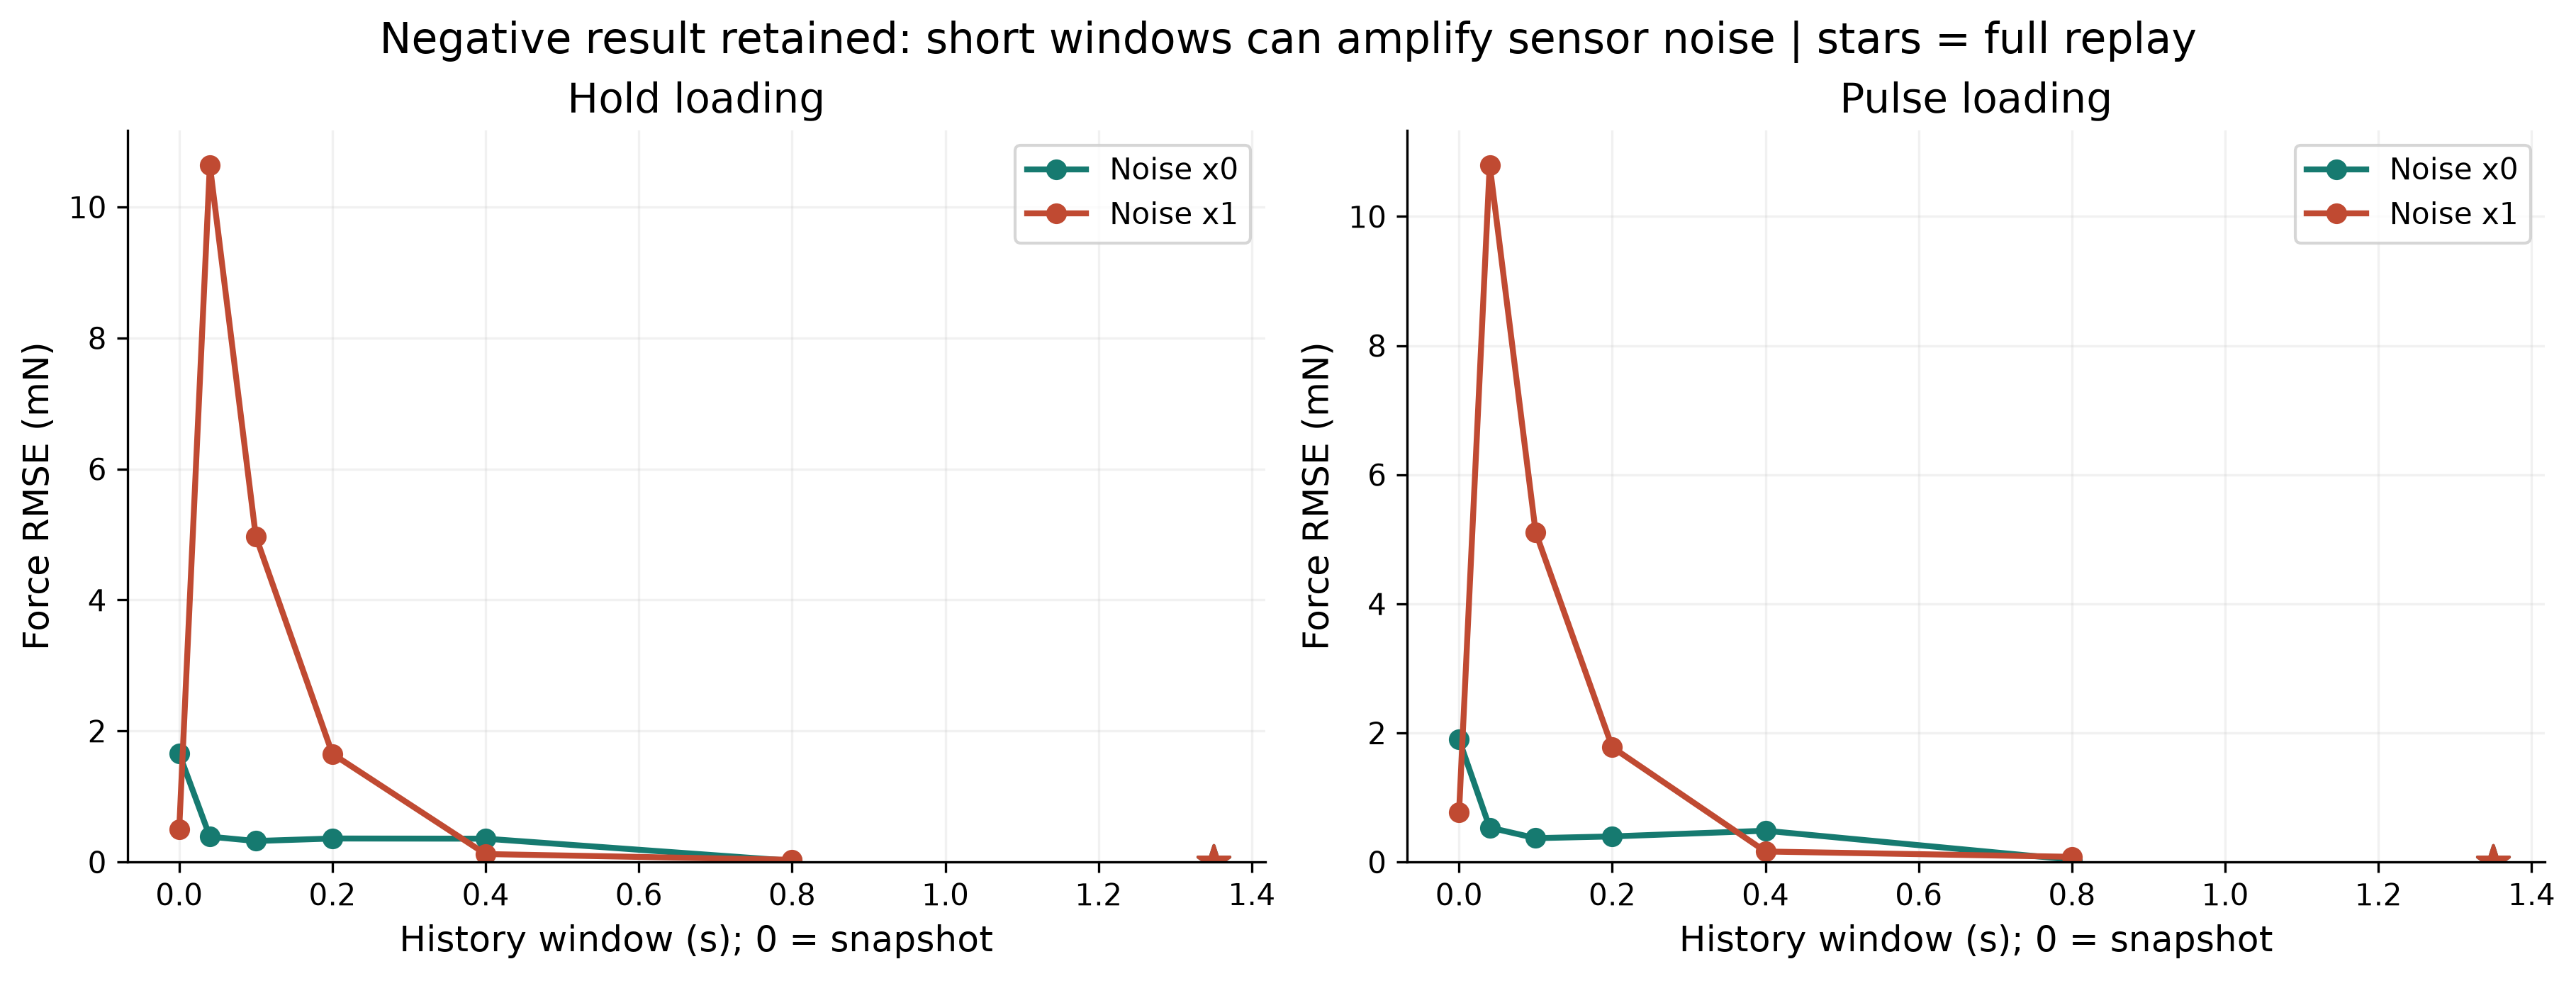

RETAINED physical overrun: histories\validation_200.npz penetration 5.0247 um > 5 um
Diagnostic doubled penalty: 2.6450 um; original is preserved, diagnostic excluded from tests.


In [8]:
noise_preview = run / 'figures/05_noise_and_excitation.png'
if noise_preview.exists():
    display(Image(filename=str(noise_preview)))
else:
    print('Use the noise/excitation dropdowns above to compute and inspect each condition.')
audit_path = run / 'physical_failures.json'
if audit_path.exists():
    audit_failures = read_json(audit_path)
    for item in audit_failures:
        print('RETAINED physical overrun:', item['path'], 'penetration %.4f um > 5 um' % item['max_penetration_um'])
        if 'diagnostic' in item:
            print('Diagnostic doubled penalty: %.4f um; original is preserved, diagnostic excluded from tests.' %
                  item['diagnostic']['max_penetration_um'])


## What this pilot supports — and what it does not

1. Fast/slow internal fields can remain after release and affect a later interaction in this synthetic spatial model.
2. Current lateral observations already constrain these fields; a similar endpoint alone does not prove exact state aliasing.
3. History length is a measured accuracy/compute tradeoff. Correct-model full replay is expected to be almost exact in the noiseless case.
4. This comparison does **not** establish necessity of a long sequence, RNN, JEPA, or a universal Markov representation.
5. Across eight test histories, the 0.2 s observer improves average prediction in the noiseless case but **loses to the snapshot
   under nominal noise**. This negative result is retained in `batch.json`; the default noiseless sweep is not the whole result.
6. These are prediction experiments, not evidence of decision benefit. E3's common-feedback negative result remains valid within its original setup.

The next experiment should first diagnose the noisy short-window fit using calibration-only regularization and additional
independent sensor-noise realizations. Then freeze that observer and test wait duration and parameter mismatch by whole histories.
A common-feedback action comparison must follow before claiming control benefit. Full articulated 3D manipulation remains a prerequisite to robot operation.

**Three-minute presentation:** 0:00–0:50 replay release/recovery/recontact; 0:50–1:40 inspect the matched endpoint and privileged internal field;
1:40–2:25 change slow to fast press and compare curves; 2:25–3:00 inspect the history sweep and state where short classical estimation is already adequate.


In [9]:
metrics = forecasts_for(run)[1]
display(widgets.HTML(table(['Default selected test parent', 'Force RMSE (mN)', 'Lateral RMSE (um)'],
    [[name, '%.4g' % (m['force_rmse_N']*1e3), '%.4g' % (m['marker_rmse_m']*1e6)]
     for name, m in metrics.items()])))
print('Notebook body elapsed: %.2f s (cached pilot and widgets included)' % (time.perf_counter()-NOTEBOOK_START))
print('Figures / GIF:', run / 'figures')
print('Full batch: python -m nr2d.cli batch')
print('Fresh pilot: python -m nr2d.cli demo --recompute')
print('Vector/raster/GIF export: python -m nr2d.cli export')
print('Configuration, raw traces, matching, inference logs and source hashes are stored in the run folder.')


HTML(value='<table><thead><tr><th style="padding:6px 12px;border-bottom:1px solid #ddd;text-align:left">Defaul…

Notebook body elapsed: 5.70 s (cached pilot and widgets included)
Figures / GIF: /workspaces/NR-material-state/runs/2d_contact/pilot_c9dd23016896/figures
Full batch: python -m nr2d.cli batch
Fresh pilot: python -m nr2d.cli demo --recompute
Vector/raster/GIF export: python -m nr2d.cli export
Configuration, raw traces, matching, inference logs and source hashes are stored in the run folder.
